In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import tensorflow as tf


In [3]:
# Load data
data = pd.read_csv('Employee_Salary_Data.csv')
print("First 5 rows of data:\n", data.head())

X = data['Years_Experience'].values.reshape(-1, 1)
y = data['Annual_Salary'].values.reshape(-1, 1)

print("\nX (Years of Experience):\n", X[:5])
print("y (Annual Salary):\n", y[:5])


First 5 rows of data:
    Years_Experience  Annual_Salary
0               0.5          37000
1               1.0          39000
2               1.2          41000
3               1.5          42000
4               1.8          44000

X (Years of Experience):
 [[0.5]
 [1. ]
 [1.2]
 [1.5]
 [1.8]]
y (Annual Salary):
 [[37000]
 [39000]
 [41000]
 [42000]
 [44000]]


In [4]:
# Split into train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTrain/Test Shapes:")
print("X_train:", X_train.shape, " | X_test:", X_test.shape)
print("y_train:", y_train.shape, " | y_test:", y_test.shape)



Train/Test Shapes:
X_train: (40, 1)  | X_test: (10, 1)
y_train: (40, 1)  | y_test: (10, 1)


In [5]:
# Scaling
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)
y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

print("\nBefore Scaling (X_train):\n", X_train[:5].ravel())
print("After Scaling (X_train_scaled):\n", X_train_scaled[:5].ravel())

print("\nBefore Scaling (y_train):\n", y_train[:5].ravel())
print("After Scaling (y_train_scaled):\n", y_train_scaled[:5].ravel())



Before Scaling (X_train):
 [ 3.8  1.8 14.   2.8  1.5]
After Scaling (X_train_scaled):
 [-0.79650331 -1.13346927  0.92202313 -0.96498629 -1.18401417]

Before Scaling (y_train):
 [ 55000  44000 107000  49000  42000]
After Scaling (y_train_scaled):
 [-0.81438441 -1.18609513  0.94279357 -1.01713571 -1.2536789 ]


In [6]:
# Define model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
print("\nModel Summary:")
model.summary()



Model Summary:


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 609 (2.38 KB)

 Trainable params: 609 (2.38 KB)

 Non-trainable params: 0 (0.00 B)

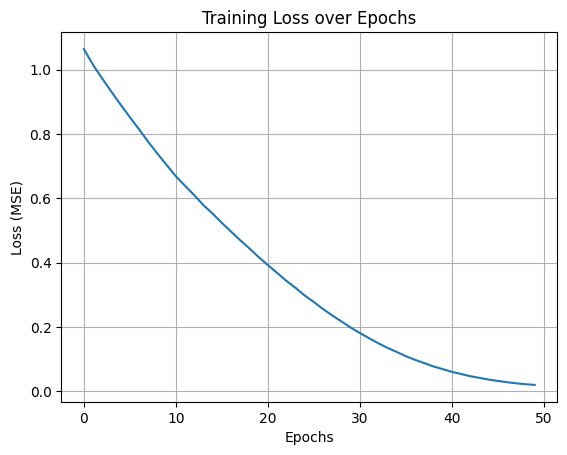

In [7]:
# Train model
history = model.fit(X_train_scaled, y_train_scaled, epochs=50, verbose=0)

# Show training loss
plt.plot(history.history['loss'])
plt.title("Training Loss over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss (MSE)")
plt.grid(True)
plt.show()


In [8]:
# Predict (scaled)
y_pred_scaled = model.predict(X_test_scaled)

# Convert back to actual salary scale
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_actual = scaler_y.inverse_transform(y_test_scaled)

print("\nSample Predictions:")
for i in range(5):
    print(f"Years Exp: {X_test[i][0]} | Actual: {y_test_actual[i][0]:.2f} | Predicted: {y_pred[i][0]:.2f}")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step

Sample Predictions:
Years Exp: 4.0 | Actual: 56000.00 | Predicted: 55196.71
Years Exp: 15.0 | Actual: 112000.00 | Predicted: 108037.16
Years Exp: 10.5 | Actual: 92000.00 | Predicted: 94033.12
Years Exp: 18.0 | Actual: 124000.00 | Predicted: 117299.64
Years Exp: 5.0 | Actual: 62000.00 | Predicted: 58998.46


In [9]:
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred))
mae = mean_absolute_error(y_test_actual, y_pred)
mape = np.mean(np.abs((y_test_actual - y_pred) / y_test_actual)) * 100
r2 = r2_score(y_test_actual, y_pred)

print("\nModel Performance:")
print("------------------")
print(f"RMSE: ${rmse:.2f}")
print(f"MAE:  ${mae:.2f}")
print(f"MAPE: {mape:.2f}%")
print(f"R²:   {r2:.4f}")



Model Performance:
------------------
RMSE: $4036.35
MAE:  $3228.14
MAPE: 3.40%
R²:   0.9723


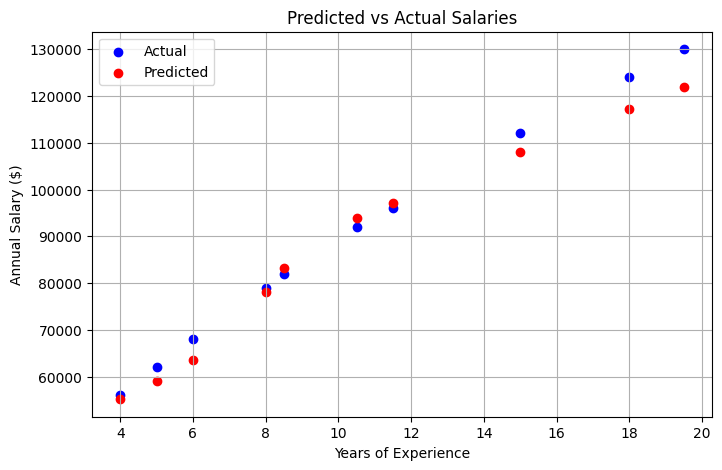

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test_actual, color='blue', label='Actual')
plt.scatter(X_test, y_pred, color='red', label='Predicted')
plt.title('Predicted vs Actual Salaries')
plt.xlabel('Years of Experience')
plt.ylabel('Annual Salary ($)')
plt.legend()
plt.grid(True)
plt.show()
